### Testing functionalities

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()

CACHE_DIR = Path.cwd().resolve().parents[1] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# Clear the cache if needed
# adapter.clear_cache()

# Imbalance
df_imbalance = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="Imbalance"
)
df_imbalance = df_imbalance.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,50), pl.time(20,00))).sort('ts_event')

# 1s Bars
df_bars = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="ohlcv-1s"
)
df_bars = df_bars.filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(20,00))).sort('ts_event')

# Statistics (for auction price)
df_stats = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="statistics"
)
# df_stats = df_stats.with_columns(pl.col('ts_event').dt.convert_time_zone("UTC"))

[GenericAdapter] Parquet cache hit: 09a704dcc7d1071e299eb6af360b5c58.parquet
[GenericAdapter] Parquet cache hit: 23cd3cce979ab29796e47e1468bf5553.parquet
[GenericAdapter] Parquet cache hit: 1f844be1ec87fbd0d0389d602155c8e5.parquet


In [2]:
df_imbalance

ts_recv,ts_event,rtype,publisher_id,instrument_id,ref_price,auction_time,cont_book_clr_price,auct_interest_clr_price,ssr_filling_price,ind_match_price,upper_collar,lower_collar,paired_qty,total_imbalance_qty,market_imbalance_qty,unpaired_qty,auction_type,side,auction_status,freeze_status,num_extensions,unpaired_side,significant_imbalance,symbol
"datetime[ns, UTC]","datetime[ns, UTC]",u8,u16,u32,f64,"datetime[ns, UTC]",f64,f64,f64,f64,f64,f64,u32,u32,u32,u32,str,str,u8,u8,u8,str,str,str
2026-04-20 19:50:00.029036342 UTC,2026-04-20 19:50:00.028867811 UTC,20,2,853,248.34,null,0.0,0.0,null,null,null,null,2739631,404589,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""~""","""AMZN"""
2026-04-20 19:50:10.023938255 UTC,2026-04-20 19:50:10.023771476 UTC,20,2,853,248.26,null,0.0,0.0,null,null,null,null,2741741,402485,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""~""","""AMZN"""
2026-04-20 19:50:20.027894258 UTC,2026-04-20 19:50:20.027726664 UTC,20,2,853,248.44,null,0.0,0.0,null,null,null,null,2733805,410527,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""~""","""AMZN"""
2026-04-20 19:50:30.002304547 UTC,2026-04-20 19:50:30.002137063 UTC,20,2,853,248.41,null,0.0,0.0,null,null,null,null,2744559,399773,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""~""","""AMZN"""
2026-04-20 19:50:40.021985493 UTC,2026-04-20 19:50:40.021818372 UTC,20,2,853,248.45,null,0.0,0.0,null,null,null,null,2739595,404737,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""~""","""AMZN"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-18 19:59:55.013624362 UTC,2026-05-18 19:59:55.013456744 UTC,20,2,853,264.76,null,264.64,264.64,null,null,null,null,3061634,40223,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""L""","""AMZN"""
2026-05-18 19:59:56.098380591 UTC,2026-05-18 19:59:56.098212694 UTC,20,2,853,264.83,null,264.64,264.64,null,null,null,null,3064265,45648,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""L""","""AMZN"""
2026-05-18 19:59:57.082355080 UTC,2026-05-18 19:59:57.082187588 UTC,20,2,853,264.82,null,264.64,264.64,null,null,null,null,3069253,40660,4294967295,4294967295,"""C""","""A""",0,0,0,"""N""","""L""","""AMZN"""


In [3]:
df_stats.filter(pl.col('stat_type') == 11).sort('ts_event')

ts_recv,ts_event,rtype,publisher_id,instrument_id,ts_ref,price,quantity,sequence,ts_in_delta,stat_type,channel_id,update_action,stat_flags,symbol
"datetime[ns, UTC]","datetime[ns, UTC]",u8,u16,u32,"datetime[ns, UTC]",f64,i32,u32,i32,u16,u16,u8,u8,str
2026-04-20 20:00:00.004103221 UTC,2026-04-20 20:00:00.003921175 UTC,24,2,853,null,248.28,4665094,759989169,182046,11,0,1,0,"""AMZN"""
2026-04-21 20:00:00.510661872 UTC,2026-04-21 20:00:00.510474868 UTC,24,2,853,null,249.91,3960917,950226256,187004,11,0,1,0,"""AMZN"""
2026-04-22 20:00:00.126288622 UTC,2026-04-22 20:00:00.126106418 UTC,24,2,853,null,255.36,4856307,709169804,182204,11,0,1,0,"""AMZN"""
2026-04-23 20:00:00.118523729 UTC,2026-04-23 20:00:00.118349658 UTC,24,2,853,null,255.08,5119398,961080164,174071,11,0,1,0,"""AMZN"""
2026-04-24 20:00:00.182973431 UTC,2026-04-24 20:00:00.182792694 UTC,24,2,853,null,263.99,4579772,802844825,180737,11,0,1,0,"""AMZN"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-12 20:00:00.411460411 UTC,2026-05-12 20:00:00.411270617 UTC,24,2,853,null,265.82,5596087,994837444,189794,11,0,1,0,"""AMZN"""
2026-05-13 20:00:00.711405969 UTC,2026-05-13 20:00:00.711235474 UTC,24,2,853,null,270.13,5535611,841142083,170495,11,0,1,0,"""AMZN"""
2026-05-14 20:00:00.464433940 UTC,2026-05-14 20:00:00.464253707 UTC,24,2,853,null,267.22,3483233,867972276,180233,11,0,1,0,"""AMZN"""


In [4]:
df_imbalance = (
    df_imbalance
    .with_columns(pl.col("ts_event").dt.truncate("1s"))
    .upsample(time_column="ts_event", every="1s")
    .fill_null(strategy='forward')
    .select(["ts_event", "ref_price", "side", "total_imbalance_qty", "cont_book_clr_price", "auct_interest_clr_price"])
    .sort('ts_event')
)
df_imbalance

ts_event,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price
"datetime[ns, UTC]",f64,str,u32,f64,f64
2026-04-20 19:50:00 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:01 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:02 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:03 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:04 UTC,248.34,"""A""",404589,0.0,0.0
…,…,…,…,…,…
2026-05-18 19:59:55 UTC,264.76,"""A""",40223,264.64,264.64
2026-05-18 19:59:56 UTC,264.83,"""A""",45648,264.64,264.64
2026-05-18 19:59:57 UTC,264.82,"""A""",40660,264.64,264.64


In [5]:
data = df_bars.select(['ts_event', 'close', 'volume']).join(df_imbalance, on='ts_event', how='left', coalesce=True).sort('ts_event')
data

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64
2026-04-20 13:30:00 UTC,249.25,705653,null,null,null,null,null
2026-04-20 13:30:01 UTC,249.26,10998,null,null,null,null,null
2026-04-20 13:30:02 UTC,249.57,23728,null,null,null,null,null
2026-04-20 13:30:03 UTC,249.78,6099,null,null,null,null,null
2026-04-20 13:30:04 UTC,249.86,8292,null,null,null,null,null
…,…,…,…,…,…,…,…
2026-05-18 19:59:56 UTC,264.82,5864,264.83,"""A""",45648,264.64,264.64
2026-05-18 19:59:57 UTC,264.81,5275,264.82,"""A""",40660,264.64,264.64
2026-05-18 19:59:58 UTC,264.85,48785,264.82,"""A""",37277,264.67,264.64


In [6]:
session_dollar_volume = (data
 .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(19,50)))
 .group_by_dynamic(
     index_column='ts_event',
     every='1d'
 ).agg(
     (pl.col('volume') * pl.col("close")).sum() #approximated using seconds closing prices
 )
).rename({"volume": "session_dollar_volume", "ts_event": "date"})

data = (
    data
    # day key (00:00:00 UTC) to match session_dollar_volume's ts_event
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .join(
        session_dollar_volume,
        on="date",
        how="left",
    )
    .with_columns(
        (
            pl.when(pl.col("side") == "A").then(-1.0)
            .when(pl.col("side") == "B").then(1.0)
            .otherwise(0.0)
            * pl.col("total_imbalance_qty") * pl.col("close")
            / pl.col("session_dollar_volume")
        ).alias("qty_signal")
    )
    .drop("date")
    .sort("ts_event")
)

data = data.fill_null(0)
data

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price,session_dollar_volume,qty_signal
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64,f64,f64
2026-04-20 13:30:00 UTC,249.25,705653,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:01 UTC,249.26,10998,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:02 UTC,249.57,23728,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:03 UTC,249.78,6099,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:04 UTC,249.86,8292,0.0,null,0,0.0,0.0,1.3228e9,0.0
…,…,…,…,…,…,…,…,…,…
2026-05-18 19:59:56 UTC,264.82,5864,264.83,"""A""",45648,264.64,264.64,1.4951e9,-0.008085
2026-05-18 19:59:57 UTC,264.81,5275,264.82,"""A""",40660,264.64,264.64,1.4951e9,-0.007202
2026-05-18 19:59:58 UTC,264.85,48785,264.82,"""A""",37277,264.67,264.64,1.4951e9,-0.006603


In [7]:
data.columns

['ts_event',
 'close',
 'volume',
 'ref_price',
 'side',
 'total_imbalance_qty',
 'cont_book_clr_price',
 'auct_interest_clr_price',
 'session_dollar_volume',
 'qty_signal']

Need to get the real close auction execution prices from the statistics df into the data df.

In [8]:
# Overwrite the 20:00:00 bar's close/volume with the real close-auction execution
# price/quantity from df_stats (stat_type 11 = closing price, one row per date).
df_close_auction = (
    df_stats
    .filter(pl.col('stat_type') == 11)
    .select(
        pl.col('ts_event').dt.date().alias('date'),
        pl.col('price').alias('auction_price'),
        pl.col('quantity').cast(pl.UInt64).alias('auction_qty'),
    )
)

data = (
    data
    .with_columns(pl.col('ts_event').dt.date().alias('date'))
    .join(df_close_auction, on='date', how='left')
    .with_columns(
        close=pl.when(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))
                .then(pl.col('auction_price'))
                .otherwise(pl.col('close')),
        volume=pl.when(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))
                .then(pl.col('auction_qty'))
                .otherwise(pl.col('volume')),
    )
    .drop(['date', 'auction_price', 'auction_qty'])
    .sort('ts_event')
)

# Sanity check: the 20:00:00 rows now carry the auction price/qty
data.filter(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price,session_dollar_volume,qty_signal
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64,f64,f64
2026-04-20 20:00:00 UTC,248.28,4665094,248.34,"""A""",26086,248.3,248.3,1.3228e9,-0.004899
2026-04-21 20:00:00 UTC,249.91,3960917,249.91,"""A""",23237,249.88,249.88,1.7977e9,-0.00323
2026-04-22 20:00:00 UTC,255.36,4856307,255.33,"""B""",47900,255.43,255.43,1.3084e9,0.009347
2026-04-23 20:00:00 UTC,255.08,5119398,255.04,"""A""",15616,255.01,255.0,1.6513e9,-0.002412
2026-04-24 20:00:00 UTC,263.99,4579772,263.94,"""B""",290521,263.99,263.99,2.1173e9,0.03623
…,…,…,…,…,…,…,…,…,…
2026-05-12 20:00:00 UTC,265.82,5596087,265.82,"""N""",0,265.82,265.82,1.3741e9,0.0
2026-05-13 20:00:00 UTC,270.13,5535611,270.17,"""N""",0,270.17,270.17,1.4809e9,0.0
2026-05-14 20:00:00 UTC,267.22,3483233,267.24,"""A""",14576,267.16,267.13,1.1743e9,-0.003317


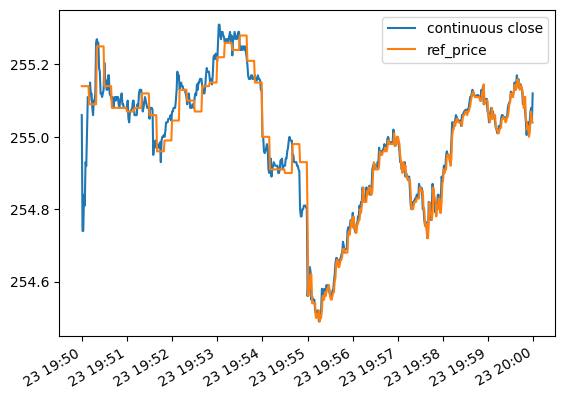

Final Closing Auction Price: 255.08


In [9]:
date = pl.date(2026,4,23)
start =  pl.time(19,50)
# end = pl.time(19,55,00)
# start =  pl.time(19,55,00)
end = pl.time(19,59,59)
h = 90
plot_data = (data
             .filter(pl.col('ts_event').dt.time().is_between(start, end),
                     pl.col('ts_event').dt.date() == date)
             .with_columns(
                 pl.col("qty_signal").diff().alias("qty_signal_diff").clip(-0.0025, 0.0025),
                 pl.col("close").pct_change(h).shift(-h).alias("fwd_return"),
                 ((pl.col("cont_book_clr_price") - pl.col('ref_price')) / pl.col('ref_price')).alias("near_ref_gap"),
                 ((pl.col("close") - pl.col("close").last()) / pl.col("close").last()).alias("cont_close_gap"))
)

from sklearn.preprocessing import StandardScaler
ss = StandardScaler()

plt.plot(plot_data.select('ts_event'), plot_data.select('close'),
         label='continuous close')

plt.plot(plot_data.select('ts_event'), plot_data.select('ref_price'),
         label='ref_price')

# plt.plot(plot_data.select('ts_event'), plot_data.select('near_ref_gap').to_numpy(),
#          label='near ref gap')

# plt.plot(plot_data.select('ts_event'), ss.fit_transform(plot_data.select(pl.col("close"))),
#          label='cont. returns')

# plt.plot(plot_data.select('ts_event'), plot_data.select("cont_close_gap"),
#          label='cont_close_gap')

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

print(f"Final Closing Auction Price: {data.filter(pl.col('ts_event').dt.date() == date).select("close")[-1].item()}")

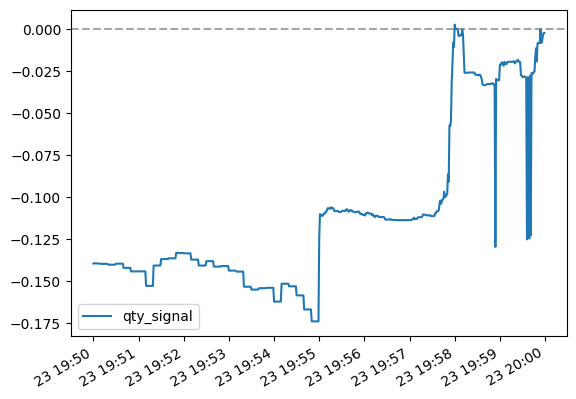

In [10]:
# plt.plot(plot_data.select('ts_event'), plot_data.select("qty_signal_diff"),
#          label='qty_signal_diff')

plt.plot(plot_data.select('ts_event'), plot_data.select("qty_signal"),
         label='qty_signal')

# plt.plot(plot_data.select('ts_event'), plot_data.select("fwd_return"),
#          label='fwd_return')

plt.axhline(y=0, color='gray', linewidth='1.5', linestyle='--', alpha=0.7)

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

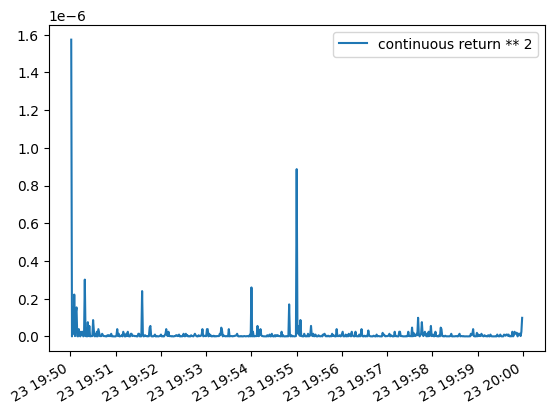

In [11]:
plt.plot(plot_data.select('ts_event'), plot_data.select(pl.col("close").pct_change()**2),
         label='continuous return ** 2')

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

Observations (seems like three things are going on here):
1. 19:00 - 19:55: the imbalance shares are published but not the near/far prices. The qty_signal (signed dollar imbalance as % of price) is a positive signal for price movement.
2. 19:55 - 20:00: Two different things happening. 
    1. If the flow is "informed" it's going where its going, and the imbalance only has an effect up to 19:55-58. Sometime in there the imbalance reverts to zero, it's price effect reverts to where it was 19:50, and the informed flow takes over.
    2. If the flow is "mechanical" (rebalancing/somebody being forced to move in close) the imbalance continues to be a good positive signal into the close.
3. There is often a volatility spike at 19:50 and most at 19:55, especially in "informed" regimes.
4. All MOC orders mus tbe in by 19:50, and all LOC orders must be in by 19:58. No order modification at the close after 19:50.


In [12]:
data.head()

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price,session_dollar_volume,qty_signal
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64,f64,f64
2026-04-20 13:30:00 UTC,249.25,705653,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:01 UTC,249.26,10998,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:02 UTC,249.57,23728,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:03 UTC,249.78,6099,0.0,null,0,0.0,0.0,1.3228e9,0.0
2026-04-20 13:30:04 UTC,249.86,8292,0.0,null,0,0.0,0.0,1.3228e9,0.0


In [13]:
close = data.group_by_dynamic(
    index_column="ts_event",
    every="1d"
).agg(
    pl.col("close").last()
).select(["ts_event", "close"])
dt = data.filter(pl.col("ts_event").dt.truncate("1s").dt.time() == pl.time(19, 54, 30)).select(["ts_event", "close"])
signal = data.filter(pl.col("ts_event").dt.time().is_between(pl.time(19,50,00), pl.time(19, 54, 30))).group_by_dynamic(
    index_column="ts_event",
    every="1d"
).agg(
    pl.col("qty_signal").mean()
).select(["ts_event", "qty_signal"])

# signal = data.filter(pl.col("ts_event").dt.truncate("1s").dt.time() == pl.time(19, 54, 30)).select(["ts_event", "qty_signal"])
return_to_close = (close.to_numpy()[:, 1] - dt.to_numpy()[:, 1]) / dt.to_numpy()[:, 1]

In [14]:
from scipy.stats import spearmanr
r, _ = spearmanr(signal.to_numpy()[:, 1], return_to_close)
r

np.float64(-0.5506493506493506)

In [15]:
times = [pl.time(19, 51, 17), pl.time(19, 53, 26), pl.time(19, 53, 10), pl.time(19, 54, 00), pl.time(19, 54, 30), pl.time(19,55,00)]
# Weird times to confirm this isn't an artifact. It should hold pretty steady from 50-55 minutes.
from scipy.stats import spearmanr
corrs = []
for time in times:
    close = data.group_by_dynamic(
        index_column="ts_event",
        every="1d").agg(
            pl.col("close").last()
            ).select(["ts_event", "close"])
    
    dt = data.filter(pl.col("ts_event").dt.truncate("1s").dt.time() == time).select(["ts_event", "close"])
    signal = data.filter(pl.col("ts_event").dt.truncate("1s").dt.time() == time).select(["ts_event", "qty_signal"])
    return_to_close = (close.to_numpy()[:, 1] - dt.to_numpy()[:, 1]) / dt.to_numpy()[:, 1]
    from scipy.stats import spearmanr
    r, _ = spearmanr(signal.to_numpy()[:, 1], return_to_close)
    corrs.append(r)

print(pl.DataFrame({"time":times, "corr":corrs}))

shape: (6, 2)
┌─────────────────────────────────┬───────────┐
│ time                            ┆ corr      │
│ ---                             ┆ ---       │
│ object                          ┆ f64       │
╞═════════════════════════════════╪═══════════╡
│ 1970-01-01 19:51:17.alias("dat… ┆ -0.436364 │
│ 1970-01-01 19:53:26.alias("dat… ┆ -0.493506 │
│ 1970-01-01 19:53:10.alias("dat… ┆ -0.532468 │
│ 1970-01-01 19:54:00.alias("dat… ┆ -0.596104 │
│ 1970-01-01 19:54:30.alias("dat… ┆ -0.587013 │
│ 1970-01-01 19:55:00.alias("dat… ┆ -0.364935 │
└─────────────────────────────────┴───────────┘


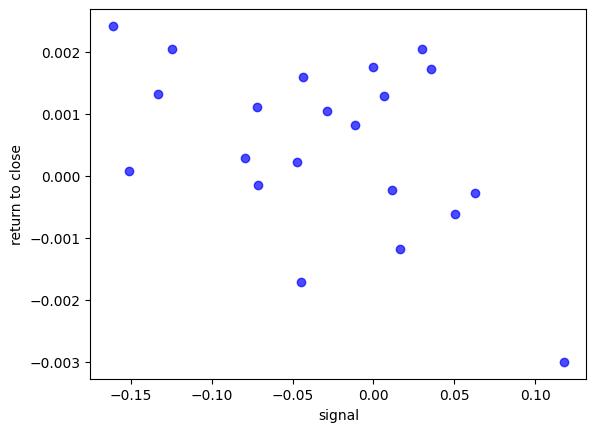

In [16]:
plt.scatter(signal.to_numpy()[:, 1], return_to_close, color='blue', alpha=0.7)
plt.xlabel("signal")
plt.ylabel("return to close")
plt.show()

In [17]:
len(signal)

21

In [18]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(signal.to_numpy()[:14, 1].reshape(-1,1), return_to_close[:14].reshape(-1,1))
y_test = return_to_close[14:].reshape(-1,1)
yhat = lr.predict(signal[14:, 1].to_numpy().reshape(-1,1))

resid = yhat - y_test

In [19]:
lr.coef_, lr.intercept_

(array([[-0.00736978]]), array([0.00041101]))

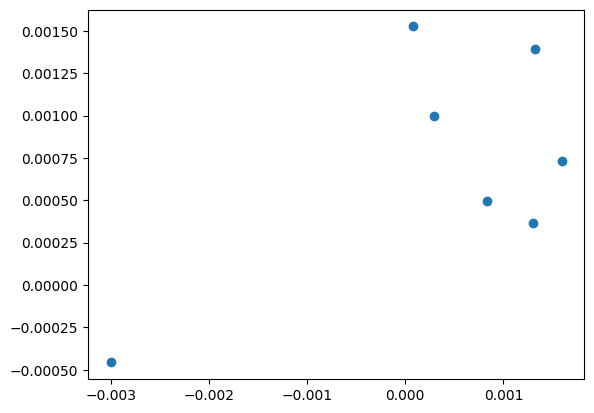

In [20]:
plt.scatter(y_test, yhat)

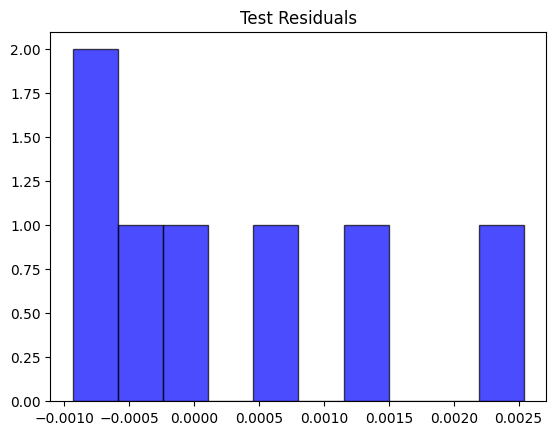

In [21]:
plt.hist(resid, color='blue', edgecolor='black', alpha=0.7)
plt.title("Test Residuals")
plt.show()

Conclusion: qty_signal at 3:54pm is a mean-reversion signal for the return to the closing auction. As of 3:55, the imbalance pulls the continuous price away from where it belongs, then whent he imbalance reverts (if it reverts) the continuous price reverts with it.
